# Flower Classification with a CNN - v2 (augmentation & dropout)

Improved version of `05_flower_cnn_v1_initial_attempt.ipynb`:

* fixes the v1 bugs (valid layer names, skips unreadable images)
* trains a baseline CNN and evaluates it
* adds a **data-augmentation** pipeline (random flip / rotation / zoom)
* adds **Dropout** to reduce overfitting

Dataset: `flower_photos` - 5 classes (roses, daisy, dandelion, sunflowers, tulips), downloaded automatically.

In [1]:
# Imports: os/PIL for files and images, TensorFlow for the model.
# import cv2
import os
import PIL
import tensorflow as tf
import cv2
import numpy as np


In [2]:
# Keras building blocks.
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential

In [3]:
# Download the flower_photos dataset (about 3,670 images in 5 classes). cache_dir='.' stores it next to the notebook.
dataset_url="https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
data_dir= tf.keras.utils.get_file('flower_photos',origin= dataset_url, cache_dir='.', untar=True)

In [4]:
# Install Pillow (image library).
pip install pillow

Note: you may need to restart the kernel to use updated packages.


In [5]:
# Path to the extracted dataset folder.
data_dir

'.\\datasets\\flower_photos'

In [6]:
# Convert the path to a pathlib.Path so we can use glob().
import pathlib
data_dir = pathlib.Path(data_dir)
data_dir

WindowsPath('datasets/flower_photos')

In [7]:
# List the first 5 image files.
list(data_dir.glob('*/*.jpg'))[:5]

[WindowsPath('datasets/flower_photos/daisy/100080576_f52e8ee070_n.jpg'),
 WindowsPath('datasets/flower_photos/daisy/10140303196_b88d3d6cec.jpg'),
 WindowsPath('datasets/flower_photos/daisy/10172379554_b296050f82_n.jpg'),
 WindowsPath('datasets/flower_photos/daisy/10172567486_2748826a8b.jpg'),
 WindowsPath('datasets/flower_photos/daisy/10172636503_21bededa75_n.jpg')]

In [8]:
# Count all .jpg images in the dataset.
image_count = len(list(data_dir.glob('*/*.jpg')))
print(image_count)

3670


In [9]:
# All rose images.
roses = list(data_dir.glob('roses/*'))
roses[:5]

[WindowsPath('datasets/flower_photos/roses/10090824183_d02c613f10_m.jpg'),
 WindowsPath('datasets/flower_photos/roses/102501987_3cdb8e5394_n.jpg'),
 WindowsPath('datasets/flower_photos/roses/10503217854_e66a804309.jpg'),
 WindowsPath('datasets/flower_photos/roses/10894627425_ec76bbc757_n.jpg'),
 WindowsPath('datasets/flower_photos/roses/110472418_87b6a3aa98_m.jpg')]

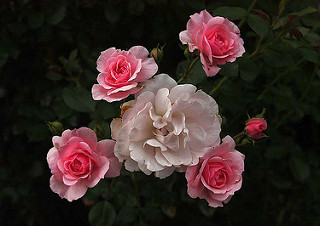

In [10]:
# Display one rose image.
PIL.Image.open(str(roses[400]))

In [11]:
# All tulip images.
tulips = list(data_dir.glob('tulips/*'))
tulips[:5]

[WindowsPath('datasets/flower_photos/tulips/100930342_92e8746431_n.jpg'),
 WindowsPath('datasets/flower_photos/tulips/10094729603_eeca3f2cb6.jpg'),
 WindowsPath('datasets/flower_photos/tulips/10094731133_94a942463c.jpg'),
 WindowsPath('datasets/flower_photos/tulips/10128546863_8de70c610d.jpg'),
 WindowsPath('datasets/flower_photos/tulips/10163955604_ae0b830975_n.jpg')]

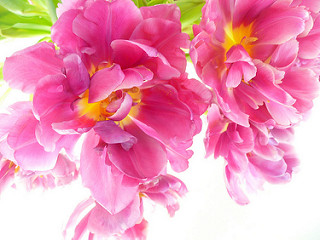

In [12]:
# Display one tulip image.
PIL.Image.open(str(tulips[400]))

In [13]:
# Dictionary: class name -> list of image paths.
flowers_images_dict = {
    'roses': list(data_dir.glob('roses/*')),
    'daisy': list(data_dir.glob('daisy/*')),
    'dandelion': list(data_dir.glob('dandelion/*')),
    'sunflowers': list(data_dir.glob('sunflowers/*')),
    'tulips': list(data_dir.glob('tulips/*')),
}


In [14]:
# Dictionary: class name -> numeric label.
flowers_labels_dict = {
    'roses':0,
    'daisy':1,
    'dandelion':2,
    'sunflowers':3,
    'tulips':4,
}
flowers_labels_dict

{'roses': 0, 'daisy': 1, 'dandelion': 2, 'sunflowers': 3, 'tulips': 4}

In [15]:
# Check the type of the stored values (a list of Path objects).
print(type(flowers_images_dict['roses']))
# print(flowers_images_dict['roses'])


<class 'list'>


In [16]:
# Install OpenCV with extra modules.
pip install opencv-contrib-python

Note: you may need to restart the kernel to use updated packages.


In [17]:
# Read one rose image with OpenCV (BGR channel order).
img = cv2.imread(str(flowers_images_dict['roses'][0]))

In [18]:
# Image shape (height, width, channels).
img.shape

(240, 179, 3)

In [19]:
# Resize to 180x180 so every image has the same size.
cv2.resize(img, (180, 180)).shape

(180, 180, 3)

In [20]:
# Build X (images) and y (labels); unreadable images (imread returns None) are skipped and reported.
X, y = [], []
for flower_name, images in flowers_images_dict.items():
    for image in images:
        img = cv2.imread(str(image))
        if img is not None:
            resized_img = cv2.resize(img, (180, 180))
            X.append(resized_img)
            y.append(flowers_labels_dict[flower_name])
        else:
            print("Image not loaded:", image)


Image not loaded: datasets\flower_photos\daisy\.ipynb_checkpoints


In [21]:
# Convert lists to NumPy arrays.
X = np.array(X)
y = np.array(y)

In [22]:
# Train/test split (default 75% / 25%) with a fixed random_state for reproducibility.
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)

In [23]:
# Scale pixel values from 0-255 to 0-1.
X_train_scaled = X_train / 255
X_test_scaled = X_test / 255

In [24]:
# Baseline CNN: three convolution + pooling blocks, then dense layers. Compiled and trained in one cell.
num_classes = 5
model = Sequential([
    # Block 1: 16 filters, 'same' padding keeps the spatial size
    layers.Conv2D(16, 3, padding='same', activation='relu'),
    layers.MaxPool2D(),
    # Block 2: 32 filters
    layers.Conv2D(32, 3, padding='same', activation='relu'),
    layers.MaxPool2D(),
    # Block 3: 64 filters
    layers.Conv2D(64, 3, padding='same', activation='relu'),
    layers.MaxPool2D(),
    # flatten the feature maps
    layers.Flatten(),
    # fully connected layer
    layers.Dense(128, activation='relu'),
    # raw scores (logits) - hence from_logits=True in the loss below
    layers.Dense(num_classes)
])

# Adam optimiser + sparse categorical cross-entropy (integer labels)
model.compile(optimizer='adam', loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=['accuracy'])
model.fit(X_train_scaled, y_train, epochs=10)

Epoch 1/10
86/86 ━━━━━━━━━━━━━━━━━━━━ 508s 6s/step - accuracy: 0.4371 - loss: 1.3181
Epoch 2/10
86/86 ━━━━━━━━━━━━━━━━━━━━ 48s 553ms/step - accuracy: 0.6097 - loss: 0.9772
Epoch 3/10
86/86 ━━━━━━━━━━━━━━━━━━━━ 42s 489ms/step - accuracy: 0.6726 - loss: 0.8325
Epoch 4/10
86/86 ━━━━━━━━━━━━━━━━━━━━ 83s 495ms/step - accuracy: 0.7442 - loss: 0.6782
Epoch 5/10
86/86 ━━━━━━━━━━━━━━━━━━━━ 42s 486ms/step - accuracy: 0.8161 - loss: 0.4984
Epoch 6/10
86/86 ━━━━━━━━━━━━━━━━━━━━ 43s 497ms/step - accuracy: 0.8975 - loss: 0.3148
Epoch 7/10
86/86 ━━━━━━━━━━━━━━━━━━━━ 43s 495ms/step - accuracy: 0.9426 - loss: 0.1887
Epoch 8/10
86/86 ━━━━━━━━━━━━━━━━━━━━ 42s 486ms/step - accuracy: 0.9713 - loss: 0.0934
Epoch 9/10
86/86 ━━━━━━━━━━━━━━━━━━━━ 56s 650ms/step - accuracy: 0.9826 - loss: 0.0637
Epoch 10/10
86/86 ━━━━━━━━━━━━━━━━━━━━ 48s 556ms/step - accuracy: 0.9876 - loss: 0.0475


In [25]:
# Evaluate on the unseen test set (a large gap vs the training accuracy indicates overfitting).
model.evaluate(X_test_scaled,y_test)

29/29 ━━━━━━━━━━━━━━━━━━━━ 6s 171ms/step - accuracy: 0.6667 - loss: 1.5789


[1.5789060592651367, 0.6666666865348816]

In [26]:
# Data augmentation: random flips, rotations and zooms create new variations of each training image, which helps against overfitting.
# NOTE: this pipeline is defined here but is never added to a model below.
img_height=180
img_width=180

data_augmentation= keras.Sequential([
    layers.RandomFlip('horizontal',
                      input_shape=(img_height,img_width,3)),
    layers.RandomRotation(0.1),
   layers.RandomZoom(0.1),
])

C:\Users\hp\anaconda3\Lib\site-packages\keras\src\layers\preprocessing\data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


(3670, 180, 180, 3)


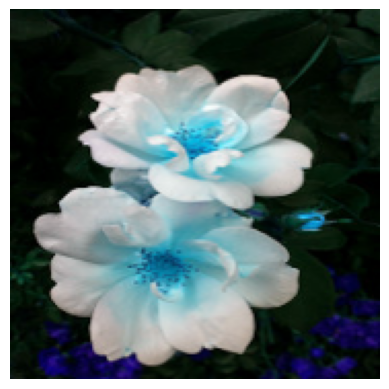

In [27]:
# Preview one image.
print(X.shape)
import matplotlib.pyplot as plt
plt.axis('off')
plt.imshow(X[0])